# Figure 1 (C, D, F, G): additional structural variants, EGFR amplicon depth, and copy number versus expression

This notebook reproduces four panels of Figure 1:

| Panel | Content |
|---|---|
| C | A chr10-chr17 rearrangement placing the *PTEN* promoter/exon 1 next to chr17 sequence (GBM09), shown as individual supporting HiFi reads |
| D | A complex *NF1* rearrangement (GBM09) shown as the full path of each supporting HiFi read |
| F | EGFR-locus read depth for the 14 EGFR-amplified tumors, as fold enrichment over local chr7 background |
| G | Purity-corrected EGFR copy number versus EGFR expression (TPM) |

Panel A (cohort schematic), panel B (oncoprint, drawn from clinical reports and manual annotation) and panel E (*BRAF*) are not reproduced here.

## 0. Setup

All inputs are read from `DATA_DIR`. Figures are written to `fig1_output/`.

In [3]:
import gzip, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker
from matplotlib import transforms
from matplotlib.patches import Rectangle, PathPatch, ConnectionPatch, FancyArrowPatch
from matplotlib.path import Path as MplPath
from matplotlib.ticker import MaxNLocator
from scipy import stats

DATA_DIR = Path("/Users/isaacxu/Downloads/ecDNA")
OUT = Path("/Users/isaacxu/Downloads/ecDNA_figs/final/fig1_output")
OUT.mkdir(exist_ok=True)

## 1. Fig 1C: *PTEN* rearrangement (GBM09)

Each supporting read is a single HiFi molecule with one alignment on chr10 (red) and one on chr17 (blue). The dashed lines are the two breakpoints, the arc is the junction, and reads are ordered by their chr10 start so they ladder into a fan. The track above the chr10 panel shows the *PTEN* promoter, exon 1 and the start of intron 1, so the breakpoint falls within the promoter/exon 1 region.

**Input** `UM164_r104_alignments.paf.tsv`: one row per alignment of each supporting read, with columns `read, chrom, qlen, qstart, qend, strand, tstart, tend`.

22 supporting reads
chr10 breakpoint: 87,863,793   chr17 breakpoint: 74,776,602


/var/folders/qz/5wwndvpx4_v74xllvh_p8vmm0000gn/T/ipykernel_12854/1648144816.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.88])


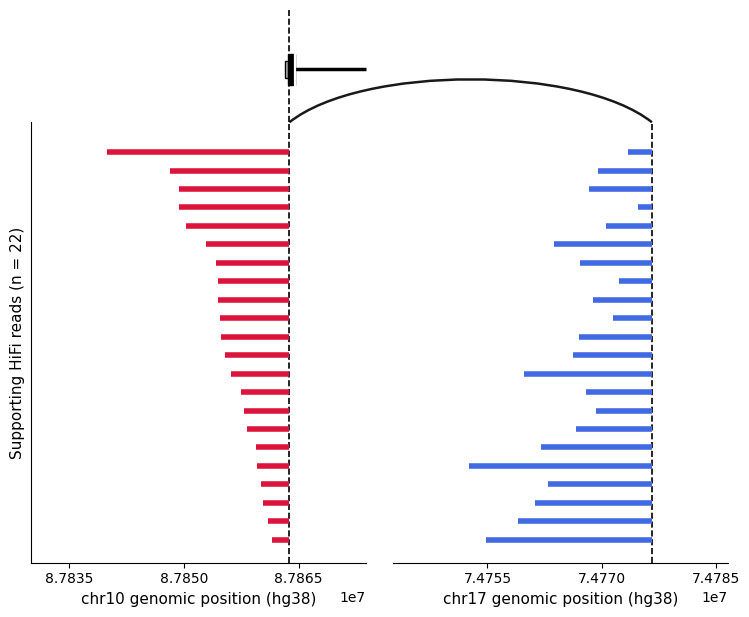

In [5]:
paf = pd.read_csv(DATA_DIR / "UM164_r104_alignments.paf.tsv", sep="\t")

BP10_LABEL = 87863793
BP10_PLOT  = 87863794   # alignment endpoint convention
BP17       = 74776602

# PTEN promoter / exon 1 coordinates (hg38)
PROMOTER_START = 87863278
PROMOTER_END   = 87863627
EXON1_START    = 87863625
INTRON1_START  = 87864548     # exon 1 ends here
START_CODON    = 87864472     # ATG, inside exon 1
PAD = 10000

# one row per read: its chr10 alignment and its chr17 alignment
rows = []
for read, g in paf.groupby("read"):
    g10 = g[g["chrom"] == "chr10"].sort_values("qstart")
    g17 = g[g["chrom"] == "chr17"].sort_values("qstart")
    if len(g10) == 0 or len(g17) == 0:
        continue
    a10, a17 = g10.iloc[0], g17.iloc[0]
    m = re.search(r"/(\d+)/ccs$", read)
    rows.append({
        "read": read, "short": m.group(1) if m else read,
        "qlen": int(max(a10["qlen"], a17["qlen"])),
        "tstart10": int(a10["tstart"]), "tend10": int(a10["tend"]),
        "tstart17": int(a17["tstart"]), "tend17": int(a17["tend"]),
        "order": "chr10→chr17" if a10["qstart"] < a17["qstart"] else "chr17→chr10",
    })
df = pd.DataFrame(rows).sort_values(["tstart10", "tstart17"]).reset_index(drop=True)

ROW_SPACING = 0.62
n = len(df)
df["y"] = [(n - i) * ROW_SPACING for i in range(n)]

x10_min, x10_max = df["tstart10"].min() - PAD, df["tend10"].max() + PAD
x17_min, x17_max = df["tstart17"].min() - PAD, df["tend17"].max() + PAD
print(f"{n} supporting reads")
print(f"chr10 breakpoint: {BP10_LABEL:,}   chr17 breakpoint: {BP17:,}")

fig = plt.figure(figsize=(9, max(4.2, 0.16 * n + 2.2)))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1], wspace=0.08)
ax10 = fig.add_subplot(gs[0, 0]); ax17 = fig.add_subplot(gs[0, 1], sharey=ax10)
ax10.set_xlim(x10_min, x10_max); ax17.set_xlim(x17_min, x17_max)

for _, r in df.iterrows():
    ax10.plot([r["tstart10"], r["tend10"]], [r["y"], r["y"]], linewidth=4, color="crimson", solid_capstyle="butt")
    ax17.plot([r["tstart17"], r["tend17"]], [r["y"], r["y"]], linewidth=4, color="royalblue", solid_capstyle="butt")
top_y = n * ROW_SPACING

ax10.axvline(BP10_PLOT, linestyle="--", linewidth=1.2, color="black", zorder=1)
ax17.axvline(BP17, linestyle="--", linewidth=1.2, color="black", zorder=1)

# PTEN promoter / exon 1 track (axes-fraction y, above the reads)
trans10 = transforms.blended_transform_factory(ax10.transData, ax10.transAxes)
TRACK_Y, TRACK_H, PROMOTER_H = 1.12, 0.07, 0.04
ax10.add_patch(Rectangle((PROMOTER_START, TRACK_Y - PROMOTER_H / 2), PROMOTER_END - PROMOTER_START, PROMOTER_H,
                         transform=trans10, facecolor="0.75", edgecolor="black", linewidth=1.0, clip_on=False, zorder=3))
ax10.add_patch(Rectangle((EXON1_START, TRACK_Y - TRACK_H / 2), INTRON1_START - EXON1_START, TRACK_H,
                         transform=trans10, facecolor="black", edgecolor="black", linewidth=1.0, clip_on=False, zorder=4))
ax10.plot([INTRON1_START, x10_max], [TRACK_Y, TRACK_Y], transform=trans10, color="black", linewidth=2.5,
          solid_capstyle="butt", zorder=3, clip_on=False)
ax10.plot([START_CODON, START_CODON], [TRACK_Y - TRACK_H / 2 - 0.012, TRACK_Y + TRACK_H / 2 + 0.012],
          transform=trans10, color="white", linewidth=1.6, zorder=5, clip_on=False)
ax10.plot([BP10_PLOT, BP10_PLOT], [1.0, TRACK_Y + TRACK_H / 2 + 0.10], transform=trans10,
          color="black", linewidth=1.2, linestyle="--", zorder=2, clip_on=False)

# junction arc between the two breakpoints
p1 = fig.transFigure.inverted().transform(trans10.transform((BP10_PLOT, 1.0)))
p2 = fig.transFigure.inverted().transform(
    transforms.blended_transform_factory(ax17.transData, ax17.transAxes).transform((BP17, 1.0)))
(x1, y1), (x2, y2) = p1, p2
arc_path = MplPath([(x1, y1), (x1 + 0.08, min(0.98, y1 + 0.10)), (x2 - 0.08, min(0.98, y2 + 0.10)), (x2, y2)],
                   [MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4])
fig.add_artist(PathPatch(arc_path, transform=fig.transFigure, facecolor="none", edgecolor="black", linewidth=1.8, alpha=0.9))

ax10.set_ylim(-0.15, top_y + 1.0)
ax10.set_yticks([]); ax10.set_ylabel(f"Supporting HiFi reads (n = {n})", fontsize=11)
ax17.tick_params(axis="y", left=False, labelleft=False)
ax10.set_xlabel("chr10 genomic position (hg38)", fontsize=11)
ax17.set_xlabel("chr17 genomic position (hg38)", fontsize=11)
for ax, nb in ((ax10, 4), (ax17, 4)):
    ax.xaxis.set_major_locator(MaxNLocator(nbins=nb))
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); ax.grid(False)
ax17.spines["left"].set_visible(False)

plt.tight_layout(rect=[0, 0.05, 1, 0.88])
#plt.savefig(OUT / "Fig1C_PTEN_reads.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Fig 1D: *NF1* rearrangement (GBM09)

Each supporting HiFi read crosses the rearrangement several times, so each is drawn as its **ordered chain of alignments** (read order, top to bottom within a read): the first alignment is upstream (chr17:31.16 Mb, near *NF1* exons 2-3), the second is a short segment near 31.366 Mb, and the third is in the *NF1* exons 55-57 region. Reads are normalised so that all run in the same direction. Dashed lines mark the inferred derivative breakpoints and the arcs show the order in which they are joined: the exon 3-side breakpoint joins the distal breakpoint, which in turn jumps back to just before exon 55.

Two reads with only two alignments are excluded as outliers.

**Input** `UM164_NF1_r218_complete_paths.tsv`: one row per read with columns `read` and `alignment_chain`; the chain lists each alignment as `q:<qstart>-<qend> <chrom>:<start>-<end>(<strand>)`.

Reads shown: 27


/var/folders/qz/5wwndvpx4_v74xllvh_p8vmm0000gn/T/ipykernel_12854/2213467928.py:103: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.91])


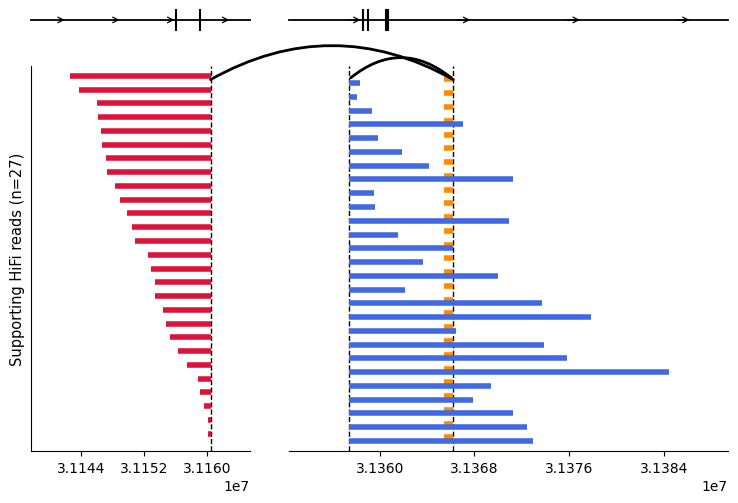

In [7]:
df0 = pd.read_csv(DATA_DIR / "UM164_NF1_r218_complete_paths.tsv", sep="\t")

# two-segment outlier reads are excluded
DROP_READS = {"m84077_260422_071043_s2/131139499/ccs", "m84077_260422_071043_s2/212009192/ccs"}
df0 = df0.loc[~df0["read"].isin(DROP_READS)].copy()

# inferred derivative junctions
BP_LEFT, BP_BACK, BP_RIGHT = 31160490, 31357375, 31366211
SMALL_START, SMALL_END = 31365452, 31366211
# approximate exon positions
EXON2, EXON3 = (31155974, 31156135), (31158995, 31159104)
EXON55, EXON56, EXON57 = (31358477, 31358627), (31358969, 31359015), (31360466, 31360718)

segment_pattern = re.compile(r"q:(\d+)-(\d+)\s+(chr[\w]+):(\d+)-(\d+)\(([+-])\)")
rows = []
for _, row in df0.iterrows():
    segs = [{"qstart": int(a), "qend": int(b), "chrom": c, "start": int(s), "end": int(e), "strand": st}
            for a, b, c, s, e, st in segment_pattern.findall(row["alignment_chain"])]
    rows.append({"read": row["read"], "segments": sorted(segs, key=lambda x: x["qstart"])})

def classify_segment(seg):
    if seg["end"] < 31200000:
        return "UP"
    if abs(seg["start"] - SMALL_START) < 5000 and abs(seg["end"] - SMALL_END) < 5000:
        return "MID"
    return "NF1"

# normalise every read to run UP -> MID -> NF1
for x in rows:
    segs, classes = x["segments"], [classify_segment(s) for s in x["segments"]]
    if classes and classes[0] == "NF1":
        segs, classes = list(reversed(segs)), list(reversed(classes))
    x["segments"], x["classes"] = segs, classes

def upstream_start(x):
    for seg, cls in zip(x["segments"], x["classes"]):
        if cls == "UP":
            return seg["start"]
    return 10**12
rows = sorted(rows, key=lambda x: (upstream_start(x), x["read"]))
n = len(rows)
print("Reads shown:", n)

up_segments = [s for x in rows for s, c in zip(x["segments"], x["classes"]) if c == "UP"]
nf_segments = [s for x in rows for s, c in zip(x["segments"], x["classes"]) if c in ("MID", "NF1")]
PAD_UP = PAD_NF = 5000
xup_min, xup_max = min(s["start"] for s in up_segments) - PAD_UP, max(s["end"] for s in up_segments) + PAD_UP
xnf_min, xnf_max = min(s["start"] for s in nf_segments) - PAD_NF, max(s["end"] for s in nf_segments) + PAD_NF

ROW_SPACING, SEG_Y_STEP = 0.72, 0.19
fig = plt.figure(figsize=(9, 5.0))
gs = fig.add_gridspec(1, 2, width_ratios=[0.9, 1.8], wspace=0.12)
ax_up = fig.add_subplot(gs[0, 0]); ax_nf = fig.add_subplot(gs[0, 1], sharey=ax_up)
ax_up.set_xlim(xup_min, xup_max); ax_nf.set_xlim(xnf_min, xnf_max)

segment_colors = ["crimson", "darkorange", "royalblue"]
for i, x in enumerate(rows):
    base_y = (n - i) * ROW_SPACING
    ys = [base_y + SEG_Y_STEP, base_y, base_y - SEG_Y_STEP]
    for j, (seg, cls, y) in enumerate(zip(x["segments"], x["classes"], ys)):
        ax = ax_up if cls == "UP" else ax_nf
        ax.plot([seg["start"], seg["end"]], [y, y], linewidth=4, color=segment_colors[j], solid_capstyle="butt", zorder=4)

ax_up.axvline(BP_LEFT, linestyle="--", linewidth=1, color="black")
ax_nf.axvline(BP_BACK, linestyle="--", linewidth=1, color="black")
ax_nf.axvline(BP_RIGHT, linestyle="--", linewidth=1, color="black")

# gene track above the reads
trans_up = transforms.blended_transform_factory(ax_up.transData, ax_up.transAxes)
trans_nf = transforms.blended_transform_factory(ax_nf.transData, ax_nf.transAxes)
TRACK_Y, EXON_H = 1.12, 0.055

def draw_gene_track(ax, trans, xmin, xmax, exons):
    ax.plot([xmin, xmax], [TRACK_Y, TRACK_Y], transform=trans, color="black", linewidth=1.3, clip_on=False)
    step = (xmax - xmin) / 8
    for xpos in [xmin + step, xmin + 3 * step, xmin + 5 * step, xmin + 7 * step]:   # + strand arrows
        ax.annotate("", xy=(xpos + step * 0.35, TRACK_Y), xytext=(xpos, TRACK_Y), xycoords=trans, textcoords=trans,
                    arrowprops=dict(arrowstyle="->", linewidth=0.9, color="black"), annotation_clip=False)
    for start, end in exons:
        ax.add_patch(Rectangle((start, TRACK_Y - EXON_H / 2), end - start, EXON_H, transform=trans,
                               facecolor="black", edgecolor="black", linewidth=0.8, clip_on=False, zorder=5))

draw_gene_track(ax_up, trans_up, xup_min, xup_max, [EXON2, EXON3])
draw_gene_track(ax_nf, trans_nf, xnf_min, xnf_max, [EXON55, EXON56, EXON57])

# two arcs: exon3-side breakpoint -> distal breakpoint (across panels), distal -> back-jump (same panel)
ARC_Y = 0.965
fig.add_artist(ConnectionPatch(xyA=(BP_LEFT, ARC_Y), coordsA=trans_up, xyB=(BP_RIGHT, ARC_Y), coordsB=trans_nf,
                               connectionstyle="arc3,rad=-0.28", arrowstyle="-", linewidth=2.0, color="black",
                               clip_on=False, zorder=10))
ax_nf.add_patch(FancyArrowPatch((BP_RIGHT, ARC_Y), (BP_BACK, ARC_Y), transform=trans_nf,
                                connectionstyle="arc3,rad=0.42", arrowstyle="-", linewidth=2.0, color="black",
                                clip_on=False, zorder=10))

ax_up.set_yticks([]); ax_nf.set_yticks([]); ax_nf.tick_params(axis="y", left=False, labelleft=False)
ax_up.set_ylim(0, n * ROW_SPACING + 0.7)
ax_up.set_ylabel(f"Supporting HiFi reads (n={n})", fontsize=10.5)
ax_up.xaxis.set_major_locator(MaxNLocator(nbins=4)); ax_nf.xaxis.set_major_locator(MaxNLocator(nbins=5))
for ax in (ax_up, ax_nf):
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); ax.grid(False)
ax_nf.spines["left"].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.91])
#plt.savefig(OUT / "Fig1D_NF1_reads.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Fig 1F: EGFR-locus depth in all EGFR-amplified tumors

For each tumor, read depth in 100-bp windows across chr7:49-59 Mb is divided by the **local chr7 background**, the median depth of chr7:49-52 Mb (a small region is masked in GBM22), giving fold enrichment. Tumors are ordered by the 60th percentile of fold enrichment within the manually defined amplicon (`MANUAL_AMP_SPANS`, set from the copy-number segments and CoRAL amplicon intervals). The yellow band is the EGFR gene and the dashed red lines mark the **minimal common region** of amplification shared by all 14 tumors. The amplicon length for each tumor is printed at the right.

**Inputs** `<sample>_Tumor_chr7_49_59mb_100bp.bed.gz` for each tumor: 100-bp mosdepth windows over chr7:49-59 Mb (commands in the appendix).

MCR: chr7:54,847,000–55,248,000  (0.40 Mb)


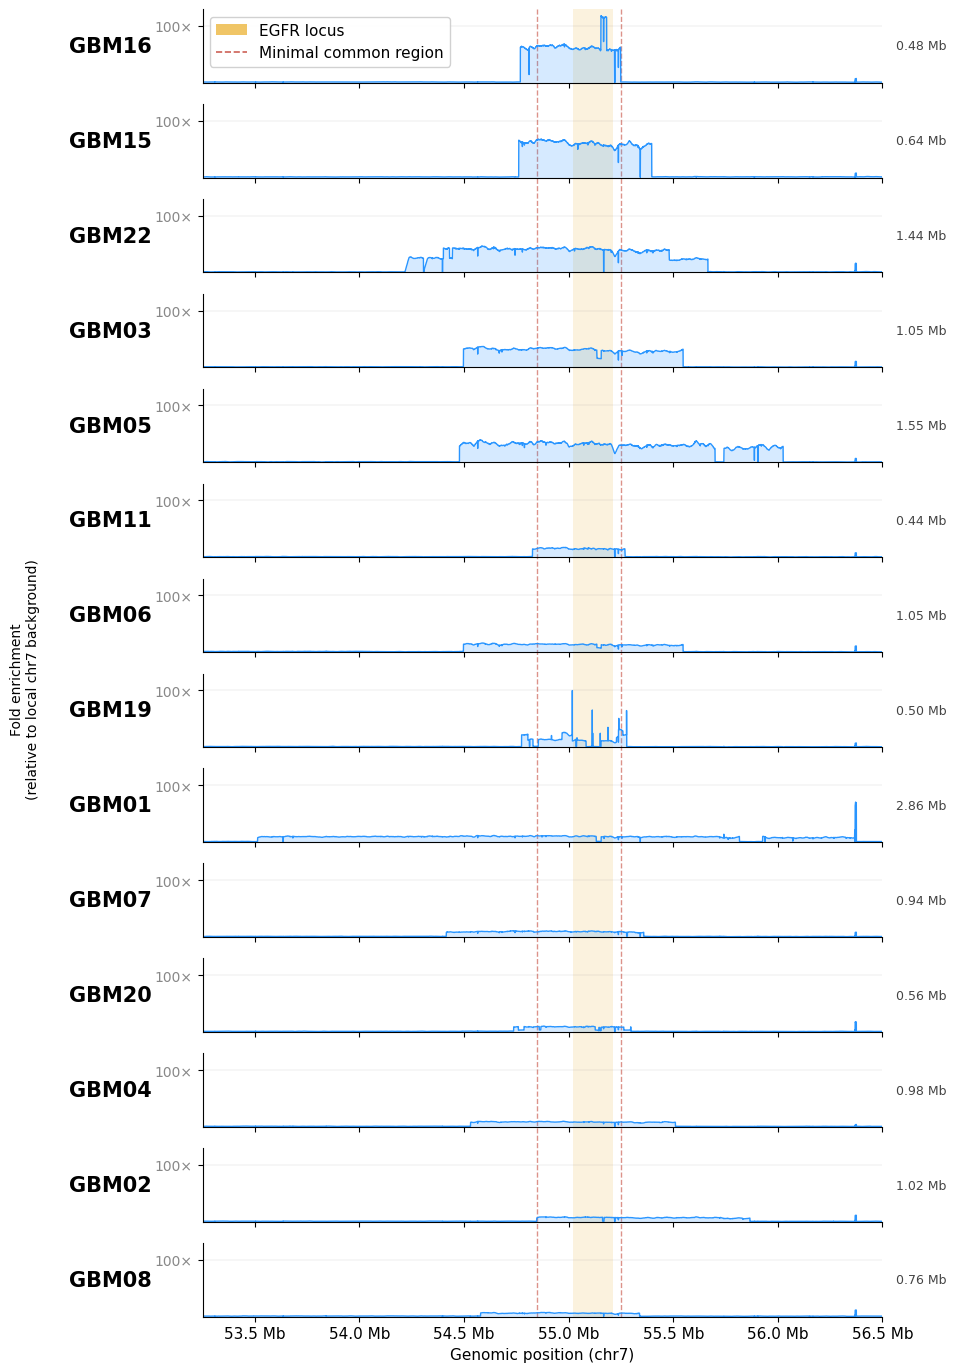

In [8]:
matplotlib.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.spines.top": False,
                            "axes.spines.right": False, "axes.linewidth": 0.8})

LOAD_XLIM, PLOT_XLIM = (49_000_000, 59_000_000), (53_250_000, 56_500_000)
EGFR_START, EGFR_END = 55_019_017, 55_211_628
BACKGROUND_REGION = (49_000_000, 52_000_000)
DOWNSAMPLE, SMOOTH_BINS = 3, 1
COLOR_TUMOR, EGFR_COLOR, MCR_COLOR = "dodgerblue", "#E69F00", "#C0392B"
EGFR_ALPHA, MCR_ALPHA = 0.13, 0.55
SHARE_Y, YMAX_QUANTILE, SORT_BY = True, 1, "amp_fold_p60"

SAMPLE_ORDER = ["UM29", "UM116", "UM124", "UM130", "UM137", "UM141", "UM146", "UM159",
                "UM170", "UM215", "UM220", "UM233", "UM244", "UM258"]

# manually defined EGFR amplicon spans (chr7, hg38)
MANUAL_AMP_SPANS = {
    "UM29":  (53_513_000, 56_375_000), "UM116": (54_847_000, 55_866_000), "UM124": (54_497_000, 55_546_500),
    "UM130": (54_531_000, 55_510_000), "UM137": (54_478_000, 56_025_000), "UM141": (54_497_000, 55_546_500),
    "UM146": (54_415_000, 55_358_500), "UM159": (54_579_000, 55_338_500), "UM170": (54_827_000, 55_268_500),
    "UM215": (54_761_500, 55_396_500), "UM220": (54_769_000, 55_248_000), "UM233": (54_775_000, 55_277_000),
    "UM244": (54_737_000, 55_296_500), "UM258": (54_221_500, 55_665_000),
}
EXCLUDE_FROM_BACKGROUND = {"UM258": [(49_722_500, 49_816_000)]}

# internal sample ID -> GBM label used in the paper
ALL_UM_SAMPLES_NUMERIC = ["UM029", "UM116", "UM124", "UM130", "UM137", "UM141", "UM146", "UM159", "UM164", "UM165",
                          "UM170", "UM176", "UM177", "UM209", "UM215", "UM220", "UM221", "UM229", "UM233", "UM244",
                          "UM245", "UM258"]
sample_label_map = {s: f"GBM{i+1:02d}" for i, s in enumerate(ALL_UM_SAMPLES_NUMERIC)}
sample_label_map["UM29"] = "GBM01"
display_label = lambda s: sample_label_map.get(s, s)

def load_bed(path, downsample=DOWNSAMPLE):
    rows = []
    with gzip.open(path, "rt") as fh:
        for line in fh:
            p = line.strip().split()
            if len(p) >= 4:
                try:
                    rows.append((int(p[1]), int(p[2]), float(p[3])))
                except ValueError:
                    continue
    df = pd.DataFrame(rows, columns=["start", "end", "depth"])
    df["pos"] = (df["start"] + df["end"]) / 2
    return df.iloc[::downsample].reset_index(drop=True)

def smooth_signal(y, window):
    if window <= 1:
        return np.asarray(y, dtype=float)
    return pd.Series(y).rolling(window=window, center=True, min_periods=1).median().values

def compute_metrics(df, sample):
    df = df.copy()
    df["depth_s"] = smooth_signal(df["depth"].values, SMOOTH_BINS)
    bg_mask = (df["pos"] >= BACKGROUND_REGION[0]) & (df["pos"] <= BACKGROUND_REGION[1])
    for s, e in EXCLUDE_FROM_BACKGROUND.get(sample, []):
        bg_mask = bg_mask & ~((df["pos"] >= s) & (df["pos"] <= e))
    bg = df.loc[bg_mask, "depth_s"].median()
    df["fold_bg"] = df["depth_s"] / bg if (np.isfinite(bg) and bg > 0) else np.nan
    amp_s, amp_e = MANUAL_AMP_SPANS.get(sample, (np.nan, np.nan))
    metrics = {"background_depth": bg, "amp_start": amp_s, "amp_end": amp_e}
    if np.isfinite(amp_s):
        amp_mask = (df["pos"] >= amp_s) & (df["pos"] <= amp_e)
        metrics.update(amp_span_bp=amp_e - amp_s, amp_span_mb=(amp_e - amp_s) / 1e6,
                       amp_fold_p60=df.loc[amp_mask, "fold_bg"].quantile(0.60))
    else:
        metrics.update(amp_span_bp=np.nan, amp_span_mb=np.nan, amp_fold_p60=np.nan)
    return df, metrics

samples_found = []
for s in SAMPLE_ORDER:
    matches = list(DATA_DIR.glob(f"{s}_Tumor_chr7_49_59mb_100bp.bed.gz"))
    if matches:
        samples_found.append((s, str(matches[0])))
    else:
        print(f"WARNING: no file for {s}")

dfs, sample_metrics, global_ymax = [], {}, 0
for sample, fpath in samples_found:
    df = load_bed(fpath)
    df = df[(df["pos"] >= LOAD_XLIM[0]) & (df["pos"] <= LOAD_XLIM[1])].copy()
    df, metrics = compute_metrics(df, sample)
    plot_df = df[(df["pos"] >= PLOT_XLIM[0]) & (df["pos"] <= PLOT_XLIM[1])]
    ymax = np.nanquantile(plot_df["fold_bg"], YMAX_QUANTILE)
    if not np.isfinite(ymax):
        ymax = 1
    dfs.append((sample, df, ymax, metrics))
    sample_metrics[sample] = metrics
    global_ymax = max(global_ymax, ymax)

# minimal common region = intersection of all amplicon spans
mcr_start = max(v[0] for v in MANUAL_AMP_SPANS.values())
mcr_end = min(v[1] for v in MANUAL_AMP_SPANS.values())
print(f"MCR: chr7:{mcr_start:,}–{mcr_end:,}  ({(mcr_end - mcr_start) / 1e6:.2f} Mb)")

if SORT_BY == "amp_fold_p60":
    dfs.sort(key=lambda x: (-sample_metrics[x[0]].get("amp_fold_p60", -np.inf), sample_metrics[x[0]].get("amp_span_bp", np.inf)))
elif SORT_BY == "manual_span_bp":
    dfs.sort(key=lambda x: (sample_metrics[x[0]].get("amp_span_bp", np.inf), -sample_metrics[x[0]].get("amp_fold_p60", -np.inf)))
else:
    order_map = {s: i for i, s in enumerate(SAMPLE_ORDER)}
    dfs.sort(key=lambda x: order_map.get(x[0], 999))

n = len(dfs)
fig, axes = plt.subplots(n, 1, figsize=(10, 14), sharex=True, sharey=SHARE_Y)
if n == 1:
    axes = [axes]
ylim_top = max(5, global_ymax * 1.10) if SHARE_Y else None

for ax, (sample, df, ymax, metrics) in zip(axes, dfs):
    yt = ylim_top if SHARE_Y else max(5, ymax * 1.10)
    plot_df = df[(df["pos"] >= PLOT_XLIM[0]) & (df["pos"] <= PLOT_XLIM[1])]
    ax.fill_between(plot_df["pos"], plot_df["fold_bg"], 0, color=COLOR_TUMOR, alpha=0.18, linewidth=0)
    ax.plot(plot_df["pos"], plot_df["fold_bg"], lw=1.0, color=COLOR_TUMOR, alpha=0.95)
    ax.text(-0.075, 0.5, display_label(sample), transform=ax.transAxes, fontsize=15, fontweight="bold",
            ha="right", va="center")
    span = sample_metrics.get(sample, {}).get("amp_span_mb", np.nan)
    if np.isfinite(span):
        ax.text(1.02, 0.5, f"{span:.2f} Mb", transform=ax.transAxes, fontsize=9, ha="left", va="center", color="#444")
    ax.set_ylim(0, yt); ax.set_xlim(*PLOT_XLIM)
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(nbins=3))
    ax.yaxis.grid(True, lw=0.3, alpha=0.35, color="grey")
    ax.set_yticks([100]); ax.set_yticklabels(["100\u00d7"], fontsize=10, color="#888")
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Genomic position (chr7)", fontsize=11)
axes[-1].xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f} Mb"))
fig.text(0.02, 0.5, "Fold enrichment\n(relative to local chr7 background)", rotation=90, va="center", ha="center", fontsize=10)
plt.tight_layout(rect=[0.04, 0, 0.96, 0.99])
fig.canvas.draw()

def to_fig_x(pos):
    return fig.transFigure.inverted().transform((axes[0].transData.transform((pos, 0))[0], 0))[0]
y0_fig, y1_fig = axes[-1].get_position().y0, axes[0].get_position().y1

# EGFR gene band and minimal-common-region lines drawn across all rows
fig.add_artist(Rectangle((to_fig_x(EGFR_START), y0_fig), to_fig_x(EGFR_END) - to_fig_x(EGFR_START), y1_fig - y0_fig,
                         transform=fig.transFigure, facecolor=EGFR_COLOR, edgecolor="none", alpha=EGFR_ALPHA, zorder=0.1))
for mcr_pos in [mcr_start, mcr_end]:
    fig.add_artist(plt.Line2D([to_fig_x(mcr_pos)] * 2, [y0_fig, y1_fig], transform=fig.transFigure, color=MCR_COLOR,
                              lw=1.0, linestyle="--", alpha=MCR_ALPHA, zorder=0.2))
for ax in axes:
    ax.set_zorder(1); ax.patch.set_alpha(0)

axes[0].legend(handles=[mpatches.Patch(facecolor=EGFR_COLOR, alpha=0.6, label="EGFR locus"),
                        plt.Line2D([0], [0], color=MCR_COLOR, lw=1.2, linestyle="--", alpha=0.8, label="Minimal common region")],
               loc="upper left", fontsize=11, frameon=True, framealpha=0.9, edgecolor="#ccc")
#plt.savefig(OUT / "Fig1F_ridgeplot_egfr.png", dpi=300)
plt.show()

## 4. Fig 1G: purity-corrected EGFR copy number versus EGFR expression

For each EGFR-amplified tumor:

* **EGFR depth** is the median 100-bp read depth over the EGFR gene (chr7:55,019,017-55,211,628), **excluding the EGFRvIII-deleted window** (chr7:55,082,955-55,154,412) so that tumors carrying the deletion are not under-counted.
* **R** = EGFR depth / genome-wide mean tumor coverage.
* **Copy number** = (2R - 2(1 - p)) / p, where p is tumor purity. This removes the contribution of diploid normal cells (2 copies) to the observed ratio. Tumor purity was estimated from **histopathology**.
* **EGFR expression** is the transcripts-per-million (TPM) of *EGFR* from RNA-seq of the same tumor.

The plot shows the Pearson correlation between copy number and expression with the regression line and its 95% confidence interval of the mean.

,gbm,egfr_depth,genome_cov,purity,cn_no_purity,cn,tpm
0,GBM01,1040.3,68.7,0.8,30.3,39.7,397.8
1,GBM02,794.2,68.2,0.8,23.3,30.4,28997.4
2,GBM03,3861.5,80.8,0.7,95.6,135.7,19734.1
3,GBM04,822.6,75.1,0.9,21.9,24.1,12450.9
4,GBM05,2144.9,62.0,0.8,69.2,91.6,27373.6
5,GBM06,1153.8,69.8,0.8,33.1,43.4,10961.6
6,GBM07,1041.0,74.4,0.7,28.0,39.1,7048.9
7,GBM08,524.1,74.3,0.7,14.1,19.3,8635.8
8,GBM11,1384.9,69.8,0.8,39.7,52.2,28956.8
9,GBM15,4686.9,76.8,0.8,122.1,152.1,26250.9


Pearson r=0.689  R2=0.474  P=0.0064   Spearman rho=0.521 (P=0.056)
CN range 19.3 (GBM08) to 197.6 (GBM16)


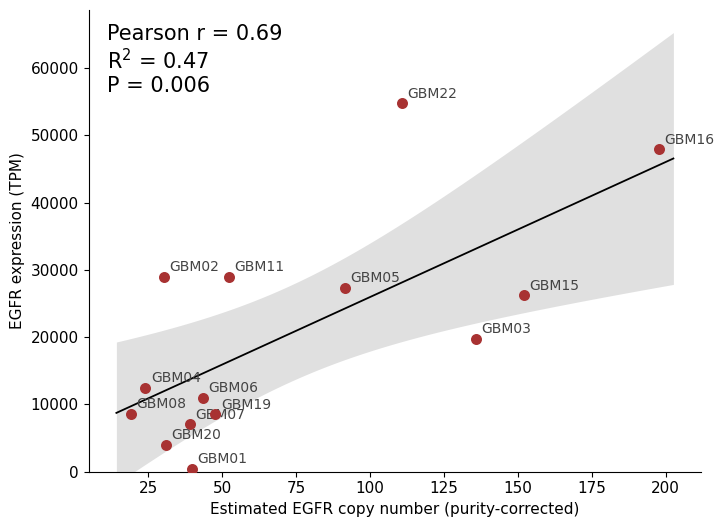

In [9]:
DATA = [
    ("GBM01", 1040.27,  68.7, 0.75, False,   397.826),
    ("GBM02",  794.22,  68.2, 0.75, False, 28997.404),
    ("GBM03", 3861.525, 80.8, 0.70, False, 19734.094),
    ("GBM04",  822.555, 75.1, 0.90, False, 12450.873),
    ("GBM05", 2144.86,  62.0, 0.75, False, 27373.600),
    ("GBM06", 1153.82,  69.8, 0.75, False, 10961.640),
    ("GBM07", 1041.045, 74.4, 0.70, False,  7048.858),
    ("GBM08",  524.065, 74.3, 0.70, False,  8635.784),
    ("GBM11", 1384.88,  69.8, 0.75, False, 28956.812),
    ("GBM15", 4686.92,  76.8, 0.80, False, 26250.933),
    ("GBM16", 5395.47,  68.1, 0.80, False, 47922.260),
    ("GBM19", 1380.415, 76.0, 0.75, False,  8557.878),
    ("GBM20",  926.23,  73.7, 0.80, False,  4014.273),
    ("GBM22", 3478.74,  78.1, 0.80, False, 54786.217),
]
df = pd.DataFrame(DATA, columns=["gbm", "egfr_depth", "genome_cov", "purity", "assumed", "tpm"])
df["R"] = df["egfr_depth"] / df["genome_cov"]
df["cn_no_purity"] = 2 * df["R"]
df["cn"] = (2 * df["R"] - 2 * (1 - df["purity"])) / df["purity"]
display(df[["gbm", "egfr_depth", "genome_cov", "purity", "cn_no_purity", "cn", "tpm"]].round(1))
df.to_csv(OUT / "Fig1G_table.csv", index=False)

x, y = df["cn"].values, df["tpm"].values
r, p = stats.pearsonr(x, y)
rho, p_rho = stats.spearmanr(x, y)
print(f"Pearson r={r:.3f}  R2={r*r:.3f}  P={p:.4f}   Spearman rho={rho:.3f} (P={p_rho:.3f})")
print(f"CN range {x.min():.1f} ({df.loc[x.argmin(), 'gbm']}) to {x.max():.1f} ({df.loc[x.argmax(), 'gbm']})")

# regression line + 95% CI of the mean
n = len(x)
slope, icpt = np.polyfit(x, y, 1)
xx = np.linspace(x.min() - 5, x.max() + 5, 200)
res = y - (slope * x + icpt)
s = np.sqrt((res**2).sum() / (n - 2))
se = s * np.sqrt(1 / n + (xx - x.mean())**2 / ((x - x.mean())**2).sum())
tcrit = stats.t.ppf(0.975, n - 2)
yy = slope * xx + icpt

matplotlib.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(7.4, 5.4))
ax.fill_between(xx, yy - tcrit * se, yy + tcrit * se, color="0.6", alpha=0.3, lw=0)
ax.plot(xx, yy, color="k", lw=1.3)
for _, row in df.iterrows():
    ax.scatter(row["cn"], row["tpm"], s=45, zorder=3, facecolor="#A83232", edgecolor="#A83232", linewidth=1.2)
    ax.annotate(row["gbm"], (row["cn"], row["tpm"]), xytext=(4, 4), textcoords="offset points", fontsize=10, color="#444")
ax.text(0.03, 0.97, f"Pearson r = {r:.2f}\nR$^2$ = {r*r:.2f}\nP = {p:.3f}", transform=ax.transAxes, va="top", fontsize=15)
ax.set_xlabel("Estimated EGFR copy number (purity-corrected)")
ax.set_ylabel("EGFR expression (TPM)")
ax.set_ylim(bottom=0)
fig.tight_layout()
#fig.savefig(OUT / "Fig1G_purity_corrected.png", dpi=300)
#fig.savefig(OUT / "Fig1G_purity_corrected.pdf")
plt.show()

## Appendix: depth files for panel F

The 100-bp depth tracks (`<sample>_Tumor_chr7_49_59mb_100bp.bed.gz`) are mosdepth windows over the chr7:49-59 Mb tumor BAM subset:

```bash
mosdepth --no-per-base --by 100 --chrom chr7 SAMPLE_Tumor_chr7_49_59mb SAMPLE_Tumor_chr7_49_59mb.bam
# output SAMPLE_Tumor_chr7_49_59mb.regions.bed.gz is renamed SAMPLE_Tumor_chr7_49_59mb_100bp.bed.gz
```